Import and dataset

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm, trange
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,MinMaxScaler
import joblib


# IMPORT FROM UTILS
from utils5 import MetaBeamMR_MLP, train_model, test_model, assess_results, predict_stress

# SETUP GPU (CUDA)
#device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#print(f"Running code on: {device.type.upper()}")
#device = "cpu"

Dataset

In [ ]:
# 1. Load dataset
column_names = [
    "B_vec", "L_vec", "TPU_R_mat", "MR_L_mat",
    "MR_R_mat", "TPU_th_mat", "Tempo_3D",
    "Strain_3D", "Stress_3D"
    ]

df = pd.read_csv('Dataset_2D.txt', sep=r'\s+', header=None, names=column_names, index_col=False)

# INPUT: B,L,STRAIN
x = df[['B_vec', 'L_vec', 'Strain_3D']].values
# OUTPUT: STRESS
y = df['Stress_3D'].values.reshape(-1, 1)

# 2. Scaler e Split (70% Train, 15% Validation, 15% Test)

scaler_x = MinMaxScaler()
scaler_y = MinMaxScaler()
x_scaled = scaler_x.fit_transform(x)
y_scaled = scaler_y.fit_transform(y)

# PRIMO SPLIT: Separiamo il 70% per il Train e lasciamo un 30% "temporaneo"
x_train, x_temp, y_train, y_temp = train_test_split(x_scaled, y_scaled, test_size=0.30, random_state=42)

# SECONDO SPLIT: Dividiamo il 30% temporaneo a metà (0.5) -> 15% Val e 15% Test
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.50, random_state=42)


#3. Tensor and DataLoader
x_train_tensor = torch.tensor(x_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)

x_val_tensor = torch.tensor(x_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32)

x_test_tensor = torch.tensor(x_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

# Creazione Dataset
train_dataset = TensorDataset(x_train_tensor, y_train_tensor)
val_dataset = TensorDataset(x_val_tensor, y_val_tensor)
test_dataset = TensorDataset(x_test_tensor, y_test_tensor)

# Creazione DataLoader
train_data = DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)
val_data = DataLoader(dataset=val_dataset, batch_size=64, shuffle=False)
test_data = DataLoader(dataset=test_dataset, batch_size=64, shuffle=False)

Training

In [ ]:
n_input = x_train_tensor.shape[1]
n_output = y_train_tensor.shape[1]


print(n_input,n_output)

3 1


In [ ]:
# 4. Initialization and model on GPU
n_input = x_train_tensor.shape[1]
n_output = y_train_tensor.shape[1]

# model on GPU
model = MetaBeamMR_MLP(n_input, n_output)

loss_criterion = nn.MSELoss()
eta = 1e-3
optimizer = optim.Adam(model.parameters(), lr=eta)
n_epochs = 100

train_loss = []
test_loss = []
val_loss = []

# 5. Ciclo di addestramento
print("Start training...")

for i in trange(n_epochs, desc="Epoch", leave=False):
    # La rete impara sul TRAIN
    model, optimizer, train_loss = train_model(model, train_data, loss_criterion, optimizer, train_loss, epoch_idx=i)
    val_loss = test_model(model, val_data, loss_criterion, val_loss)


Start training...


Epoch:   0%|          | 0/100 [00:00<?, ?it/s]

Training:   0%|          | 0/464 [00:00<?, ?it/s]

Training:   0%|          | 0/464 [00:00<?, ?it/s]

Training:   0%|          | 0/464 [00:00<?, ?it/s]

Training:   0%|          | 0/464 [00:00<?, ?it/s]

... (92 outputs left out)

Training:   0%|          | 0/464 [00:00<?, ?it/s]

Training:   0%|          | 0/464 [00:00<?, ?it/s]

Training:   0%|          | 0/464 [00:00<?, ?it/s]

Training:   0%|          | 0/464 [00:00<?, ?it/s]

Test and Validatio

In [ ]:
print(x_train_tensor.shape)

torch.Size([29694, 3])


In [ ]:
def assess_results(model, X, y, data_type):
    model.eval()
    with torch.no_grad():
        # Sposta l'input sulla GPU per la predizione
        # X = X.to(device)
        # La predizione avviene su GPU, riportiamo il risultato su CPU per matplotlib/numpy
        y_hat = model(X)
        # Assicuriamoci che anche y sia su CPU
        # y = y.cpu()

        # Convert tensors to numpy for plotting
        y_hat_np = y_hat.numpy()
        y_np = y.numpy()

        # Prediction and plotting (Scatter with Parity Line)
        plt.figure(figsize=(5, 5))  # Square aspect ratio works best for parity plots

        # 1. Plot the actual predictions
        plt.scatter(y_hat_np, y_np, alpha=0.5, color='#1f77b4', label='Predictions')

        # 2. CRITICAL: Compute dynamic limits for the perfect prediction line
        min_val = min(y_hat_np.min(), y_np.min())
        max_val = max(y_hat_np.max(), y_np.max())

        # 3. Plot the perfect prediction reference line (y = x)
        plt.plot([min_val, max_val], [min_val, max_val],
                 color='red', linestyle='--', linewidth=1.5, alpha=0.8, label='Perfect Prediction (y=x)')

        # Symmetrical and square plot boundaries
        plt.xlim(min_val, max_val)
        plt.ylim(min_val, max_val)

        plt.xlabel('Predicted output')
        plt.ylabel('True output')
        plt.grid(True, linestyle=':', alpha=0.6)
        plt.title(f'R² Parity Plot: {data_type} Dataset', fontweight='bold')
        plt.legend(loc='upper left')

        plt.tight_layout()
        plt.show(block=False)
        plt.pause(0.1)

        # RMSE calculation
        mse = torch.mean((y_hat - y) ** 2)
        rmse = torch.sqrt(mse)

        # R2 calculation
        # Note: Added unbiased=True option to match standard statistical R2 definitions
        total_variance = torch.var(y, unbiased=True)
        residual_variance = torch.mean((y_hat - y) ** 2)
        R2 = 1 - residual_variance / total_variance

    return rmse.item(), R2.item()


--- RISULTATI ---


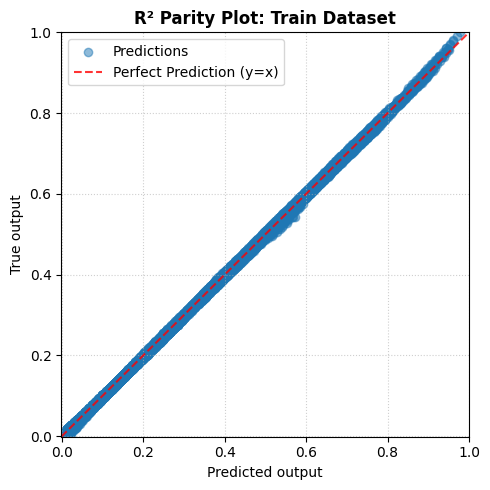

TRAIN      -> RMSE = 0.00342 | R2 = 1.000


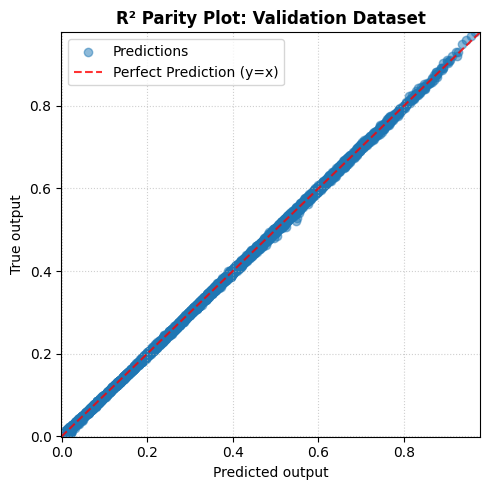

VALIDATION -> RMSE = 0.00346 | R2 = 1.000


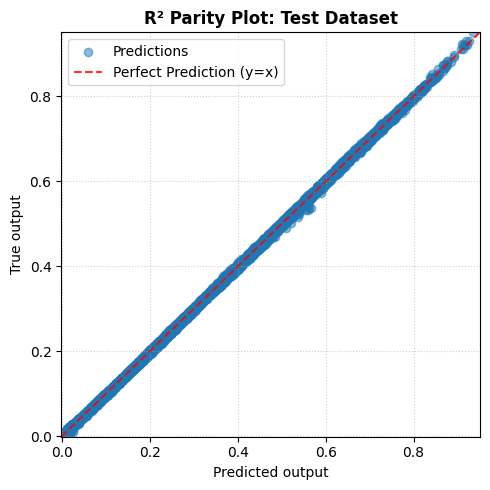

TEST       -> RMSE = 0.00346 | R2 = 1.000


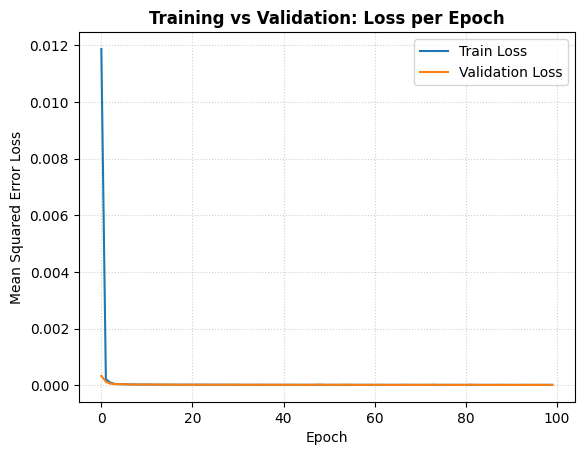


--- TEST DI PREDIZIONE ---
Stress predetto per (B=1.2, L=40, Strain=0.05195): 387703.9688


In [ ]:
# 6. Valutazione Finale

# train
print('\n--- RISULTATI ---')
rmse_train, R2_train = assess_results(model, x_train_tensor, y_train_tensor.view(-1,1), 'Train')
print(f"TRAIN      -> RMSE = {rmse_train:.5f} | R2 = {R2_train:.3f}")

# validation
rmse_val, R2_val = assess_results(model, x_val_tensor, y_val_tensor.view(-1,1), 'Validation')
print(f"VALIDATION -> RMSE = {rmse_val:.5f} | R2 = {R2_val:.3f}")

# test
# IL VERO TEST (l'esame di Stato!)
rmse_test, R2_test = assess_results(model, x_test_tensor, y_test_tensor.view(-1,1), 'Test')
print(f"TEST       -> RMSE = {rmse_test:.5f} | R2 = {R2_test:.3f}")

# Plot delle Loss (ora confrontiamo Train e Validation)

plt.figure()
plt.plot(train_loss, label="Train Loss")
plt.plot(val_loss, label="Validation Loss")  # <-- Modificato
plt.title("Training vs Validation: Loss per Epoch", fontweight='bold')
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error Loss")

# ADDED GRID
plt.grid(True, linestyle=":", alpha=0.6)

plt.legend()
plt.show(block=False)
plt.pause(0.1)

# 7. Predizione di un nuovo valore
new_stress = predict_stress(model, scaler_x, scaler_y, B=1.2, L=40, Strain=0.05195)
print(f"\n--- TEST DI PREDIZIONE ---")
print(f"Stress predetto per (B=1.2, L=40, Strain=0.05195): {new_stress:.4f}")


In [ ]:
# visualization in real scale

x_test # B,L,sigma ( 3 x len_test)
y_test # stress (1 x len_test)


array([[0.43685008],
       [0.01992948],
       [0.0438909 ],
       ...,
       [0.50975395],
       [0.32467358],
       [0.3224909 ]])

In [ ]:
def predict_all_test(model, scaler_x, scaler_y, x_test_scaled):
    """
    Calcola le predizioni sull'intero dataset di test scalato
    e restituisce sia gli input che gli output convertiti alla scala fisica reale.
    """
    model.eval()

    # 1. Convertiamo l'intero numpy array di test in tensore e lo spostiamo sul device
    input_tensor = torch.FloatTensor(x_test_scaled)

    with torch.no_grad():
        # 2. Predizione simultanea su tutto il dataset
        scaled_predictions = model(input_tensor).cpu().numpy()

    # 3. Riportiamo i dati alla scala fisica originaria usando gli inversi degli scaler
    x_physical = scaler_x.inverse_transform(x_test_scaled)
    y_pred_physical = scaler_y.inverse_transform(scaled_predictions)

    return x_physical, y_pred_physical

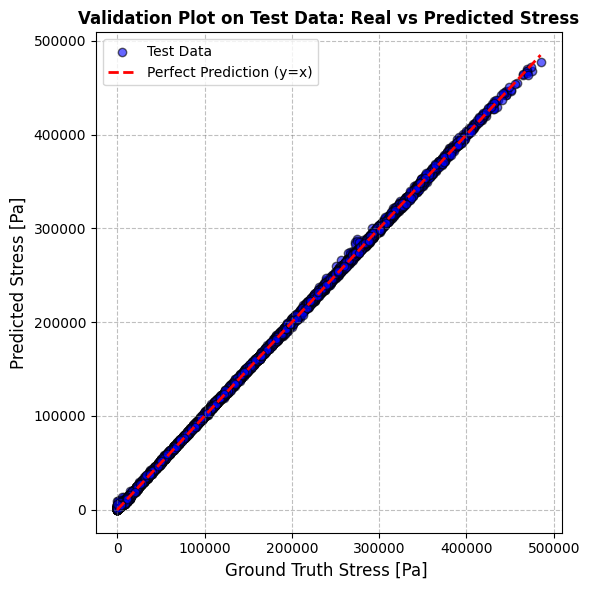

In [ ]:
# 1. Ricaviamo i valori fisici reali anche per le Y di test (che al momento sono scalate)
y_true_physical = scaler_y.inverse_transform(y_test)

# 2. Calcoliamo tutte le predizioni fisiche usando la nuova funzione
x_phys, y_pred_phys = predict_all_test(model, scaler_x, scaler_y, x_test)

# 3. Creazione del grafico Scatter "True vs Predicted"
plt.figure(figsize=(6, 6))

# Plottiamo i punti reali sull'asse X e quelli predetti sull'asse Y
plt.scatter(y_true_physical, y_pred_phys, color='blue', alpha=0.6, edgecolors='k', label='Test Data')

# Disegniamo la linea di perfetta predizione (Y = X) come riferimento teorico
min_val = min(y_true_physical.min(), y_pred_phys.min())
max_val = max(y_true_physical.max(), y_pred_phys.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Perfect Prediction (y=x)')

# Formattazione del grafico con la griglia
plt.xlabel('Ground Truth Stress [Pa] ', fontsize=12)
plt.ylabel('Predicted Stress [Pa]', fontsize=12)
plt.title('Validation Plot on Test Data: Real vs Predicted Stress', fontsize=12, fontweight='bold')

# Configurazione griglia leggera e tratteggiata
plt.grid(True, linestyle='--', alpha=0.5, color='gray')

plt.legend()
plt.tight_layout()
plt.show()

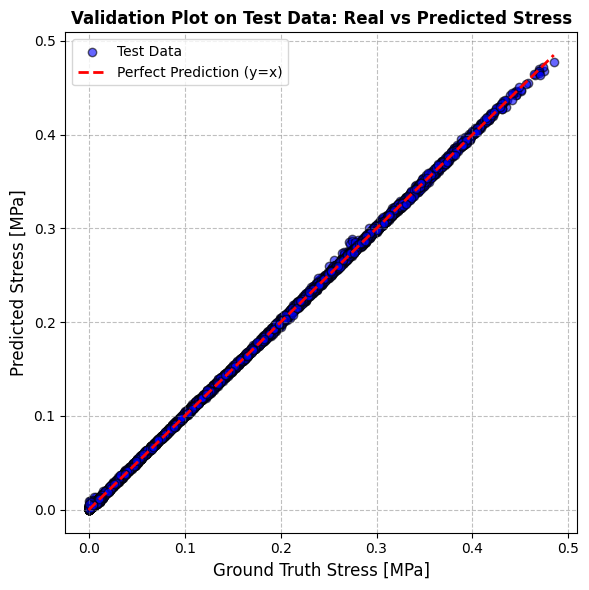

In [ ]:
# ==============================================================================
# CREAZIONE DEL GRAFICO SCATTER "TRUE VS PREDICTED" (IN MPa)
# ==============================================================================

# 1. Ricaviamo i valori fisici reali e convertiamoli in MPa
y_true_physical_mpa = scaler_y.inverse_transform(y_test) / 1e6

# 2. Calcoliamo tutte le predizioni fisiche e convertiamole in MPa
x_phys, y_pred_phys = predict_all_test(model, scaler_x, scaler_y, x_test)
y_pred_phys_mpa = y_pred_phys / 1e6

# 3. Creazione del grafico Scatter "True vs Predicted"
plt.figure(figsize=(6, 6))

# Plottiamo i punti reali (X) e predetti (Y) in MPa
plt.scatter(
    y_true_physical_mpa,
    y_pred_phys_mpa,
    color='blue',
    alpha=0.6,
    edgecolors='k',
    label='Test Data'
)

# Disegniamo la linea di perfetta predizione (Y = X) coerente con le nuove unità in MPa
min_val = min(y_true_physical_mpa.min(), y_pred_phys_mpa.min())
max_val = max(y_true_physical_mpa.max(), y_pred_phys_mpa.max())
plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color='red',
    linestyle='--',
    linewidth=2,
    label='Perfect Prediction (y=x)'
)

# Formattazione del grafico con la griglia e le nuove unità [MPa]
plt.xlabel('Ground Truth Stress [MPa]', fontsize=12)  # 🌟 Aggiornato in MPa
plt.ylabel('Predicted Stress [MPa]', fontsize=12)     # 🌟 Aggiornato in MPa
plt.title('Validation Plot on Test Data: Real vs Predicted Stress', fontsize=12, fontweight='bold')

# Configurazione griglia leggera e tratteggiata
plt.grid(True, linestyle='--', alpha=0.5, color='gray')

plt.legend()
plt.tight_layout()
plt.show()

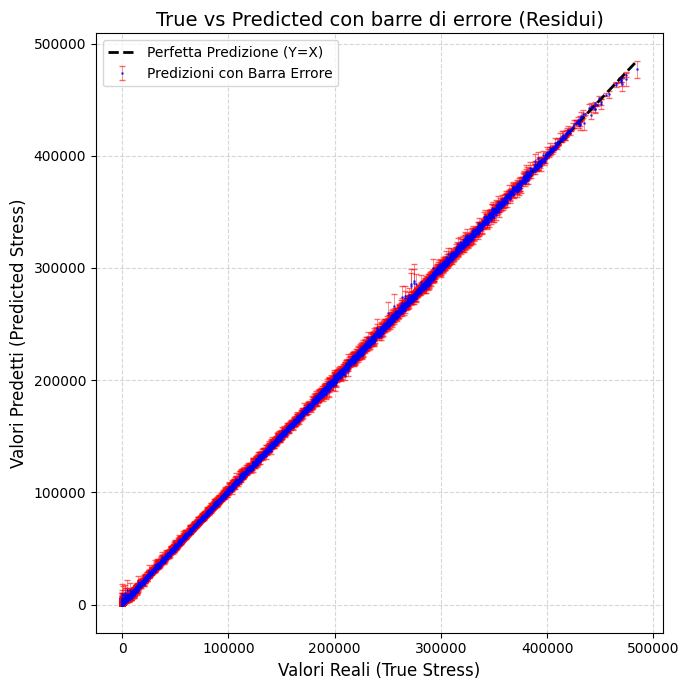

In [ ]:
# 1. Ricaviamo i valori fisici reali e predetti (in scala reale)
y_true_physical = scaler_y.inverse_transform(y_test).flatten()
x_phys, y_pred_phys = predict_all_test(model, scaler_x, scaler_y, x_test)
y_pred_physical = y_pred_phys.flatten()

# 2. Calcoliamo l'errore (la differenza assoluta o con segno) per ogni punto
# Questo determinerà la lunghezza della barra di errore
errori = np.abs(y_true_physical - y_pred_physical)

plt.figure(figsize=(7, 7))

# 3. Usiamo plt.errorbar
# Mettiamo i valori REALI sull'asse X e i valori PREDETTI sull'asse Y.
# yerr=errori dice di disegnare una barra verticale lunga quanto l'errore.
plt.errorbar(y_true_physical, y_pred_physical, yerr=errori, fmt='o',
             color='blue', ecolor='red', ms = 1, elinewidth=0.5, capsize=2, alpha=0.6,
             label='Predizioni con Barra Errore')

# 4. Disegnamo la linea ideale Y = X di perfetta predizione
min_val = min(y_true_physical.min(), y_pred_physical.min())
max_val = max(y_true_physical.max(), y_pred_physical.max())
plt.plot([min_val, max_val], [min_val, max_val], color='black', linestyle='--', linewidth=2, label='Perfetta Predizione (Y=X)')

# Formattazione e Griglia
plt.xlabel('Valori Reali (True Stress)', fontsize=12)
plt.ylabel('Valori Predetti (Predicted Stress)', fontsize=12)
plt.title('True vs Predicted con barre di errore (Residui)', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

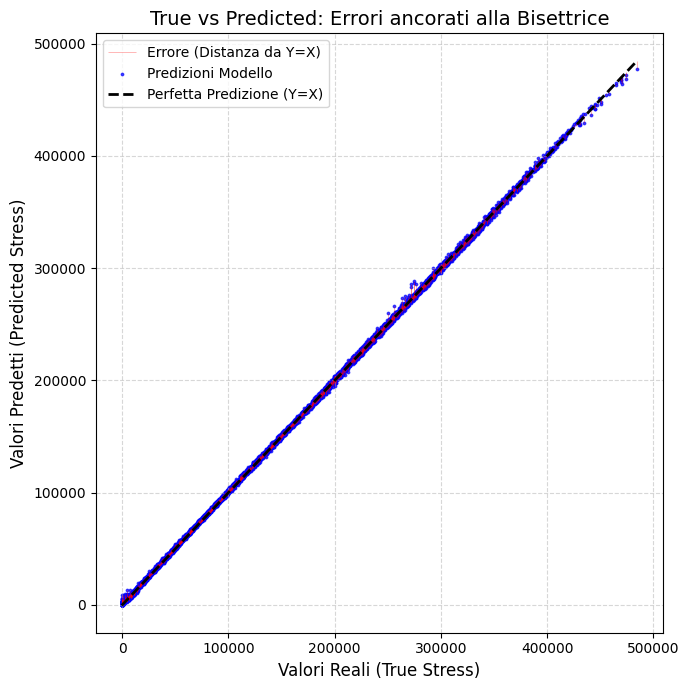

In [ ]:
# 1. Ricaviamo i valori fisici reali e predetti (in scala reale)
y_true_physical = scaler_y.inverse_transform(y_test).flatten()
x_phys, y_pred_phys = predict_all_test(model, scaler_x, scaler_y, x_test)
y_pred_physical = y_pred_phys.flatten()

plt.figure(figsize=(7, 7))

# 2. DISEGNIAMO LE REFFE DELL'ERRORE (Da Y_true a Y_pred)
# plt.vlines vuole:
#   x = la coordinata x del punto (il valore True)
#   ymin = da dove parte la linea verticale (il valore True sulla bisettrice)
#   ymax = dove arriva la linea verticale (la predizione della rete)
plt.vlines(x=y_true_physical, ymin=y_true_physical, ymax=y_pred_physical,
           colors='red', linewidth=0.4, alpha=0.5, label='Errore (Distanza da Y=X)')

# 3. DISEGNIAMO I PALLINI BLU (Le predizioni effettive)
# Li mettiamo sopra le linee così rimangono ben visibili in primo piano
plt.scatter(y_true_physical, y_pred_physical, color='blue', s=3, alpha=0.7, label='Predizioni Modello')

# 4. Disegnamo la linea ideale Y = X di perfetta predizione
min_val = min(y_true_physical.min(), y_pred_physical.min())
max_val = max(y_true_physical.max(), y_pred_physical.max())
plt.plot([min_val, max_val], [min_val, max_val], color='black', linestyle='--', linewidth=2, label='Perfetta Predizione (Y=X)')

# Formattazione e Griglia
plt.xlabel('Valori Reali (True Stress)', fontsize=12)
plt.ylabel('Valori Predetti (Predicted Stress)', fontsize=12)
plt.title('True vs Predicted: Errori ancorati alla Bisettrice', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.5)

# Per evitare che la legenda ripeta la riga dell'errore per ogni singolo punto
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys())

plt.tight_layout()
plt.show()

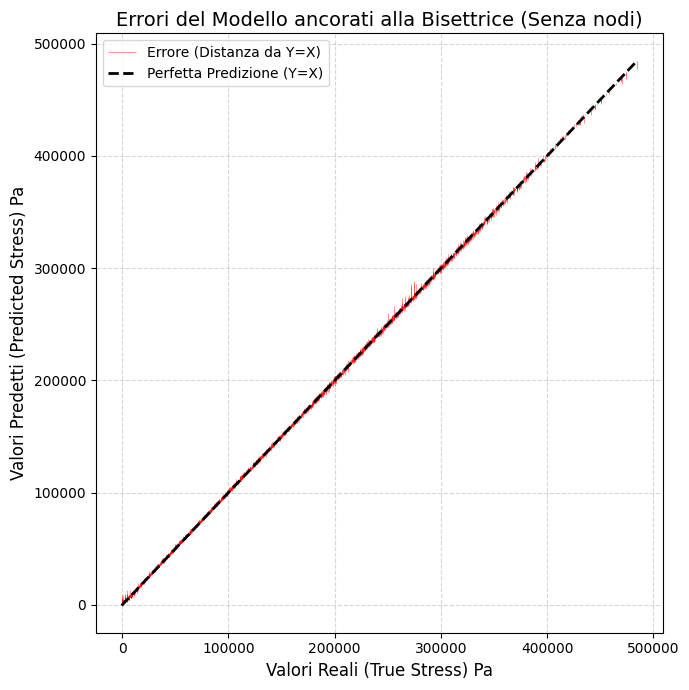

In [ ]:
# 1. Ricaviamo i valori fisici reali e predetti (in scala reale)
y_true_physical = scaler_y.inverse_transform(y_test).flatten()
x_phys, y_pred_phys = predict_all_test(model, scaler_x, scaler_y, x_test)
y_pred_physical = y_pred_phys.flatten()

plt.figure(figsize=(7, 7))

# 2. DISEGNIAMO LE REFFE DELL'ERRORE (Solo le linee rosse)
plt.vlines(x=y_true_physical, ymin=y_true_physical, ymax=y_pred_physical,
           colors='red', linewidth=0.5, alpha=0.6, label='Errore (Distanza da Y=X)')

# [ NOTA: La riga plt.scatter è stata rimossa per eliminare i pallini blu ]

# 3. Disegnamo la linea ideale Y = X di perfetta predizione
min_val = min(y_true_physical.min(), y_pred_physical.min())
max_val = max(y_true_physical.max(), y_pred_physical.max())
plt.plot([min_val, max_val], [min_val, max_val], color='black', linestyle='--', linewidth=2, label='Perfetta Predizione (Y=X)')

# Formattazione e Griglia
plt.xlabel('Valori Reali (True Stress) Pa', fontsize=12)
plt.ylabel('Valori Predetti (Predicted Stress) Pa', fontsize=12)
plt.title('Errori del Modello ancorati alla Bisettrice (Senza nodi)', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.5)

# Sistemazione legenda pulita
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys())

plt.tight_layout()
plt.show()

Saving model and scaler

In [ ]:
# ==========================================
# SALVATAGGIO DEL MODELLO ADDESTRATO E SCALER
# ==========================================
# 1. Salviamo i pesi (state_dict) del modello
model_save_path = "metabeam_mlp_model.pth"
torch.save(model.state_dict(), model_save_path)
print(f"\nModello salvato con successo in: {model_save_path}")

# 2. Salviamo gli scaler usati per normalizzare i dati
joblib.dump(scaler_x, 'scaler_x.pkl')
joblib.dump(scaler_y, 'scaler_y.pkl')
print("Scaler (X e Y) salvati con successo in file .pkl!")

# ==========================================
# FInal stop for plots and results
# ==========================================
# Questo mantiene vivo lo script e ti lascia guardare tutti i grafici aperti!
# print("\nElaborazione finita. Chiudi le finestre dei grafici per terminare il programma.")
# plt.show()


Modello salvato con successo in: metabeam_mlp_model.pth
Scaler (X e Y) salvati con successo in file .pkl!
